In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
import yaml

from matplotlib.colors import ListedColormap, BoundaryNorm

In [3]:
BASE_DIR = Path.cwd().resolve()

if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent
elif (BASE_DIR / "ml" / "configs").is_dir():
    BASE_DIR = BASE_DIR / "ml"

CONFIG_PATH = BASE_DIR / "configs" / "dataset.yaml"

with open(CONFIG_PATH, "r", encoding="utf-8") as file:
    config = yaml.safe_load(file)["dataset"]

DATA_DIR = BASE_DIR / config["root_dir"]

IMAGE_DIR = DATA_DIR / config["image_dir"]
MASK_DIR = DATA_DIR / config["mask_dir"]

print("Base directory:", BASE_DIR)
print("Image directory:", IMAGE_DIR)
print("Mask directory:", MASK_DIR)

Base directory: D:\FloodVision-AI\ml
Image directory: D:\FloodVision-AI\ml\data\raw\Sen1Floods11\S1Hand
Mask directory: D:\FloodVision-AI\ml\data\raw\Sen1Floods11\LabelHand


In [4]:
image_files = sorted(IMAGE_DIR.glob("*.tif"))
mask_files = sorted(MASK_DIR.glob("*.tif"))

print("Total satellite images:", len(image_files))
print("Total segmentation masks:", len(mask_files))

assert image_files, "No satellite images found"
assert mask_files, "No masks found"

print("\nSample image:", image_files[0].name)
print("Sample mask:", mask_files[0].name)

Total satellite images: 446
Total segmentation masks: 446

Sample image: Bolivia_103757_S1Hand.tif
Sample mask: Bolivia_103757_LabelHand.tif


In [5]:
images = {
    path.stem.removesuffix("_S1Hand"): path
    for path in image_files
}

masks = {
    path.stem.removesuffix("_LabelHand"): path
    for path in mask_files
}

common_ids = sorted(images.keys() & masks.keys())

missing_masks = images.keys() - masks.keys()
missing_images = masks.keys() - images.keys()

print("Matched pairs:", len(common_ids))
print("Missing masks:", len(missing_masks))
print("Missing images:", len(missing_images))

assert len(common_ids) == 446
assert not missing_masks
assert not missing_images

Matched pairs: 446
Missing masks: 0
Missing images: 0


In [7]:
sample_id = common_ids[0]

image_path = images[sample_id]
mask_path = masks[sample_id]

with rasterio.open(image_path) as src:
    image = src.read()

    print("Image shape:", image.shape)
    print("Data type:", image.dtype)
    print("CRS:", src.crs)
    print("Resolution:", src.res)
    print("Bounds:", src.bounds)

with rasterio.open(mask_path) as src:
    mask = src.read(1)

    print("\nMask shape:", mask.shape)
    print("Unique labels:", np.unique(mask))

Image shape: (2, 512, 512)
Data type: float32
CRS: EPSG:4326
Resolution: (8.983152841195215e-05, 8.983152841195215e-05)
Bounds: BoundingBox(left=-65.26512067407877, bottom=-14.258060189545045, right=-65.21912693153185, top=-14.212066446998126)

Mask shape: (512, 512)
Unique labels: [-1  0  1]


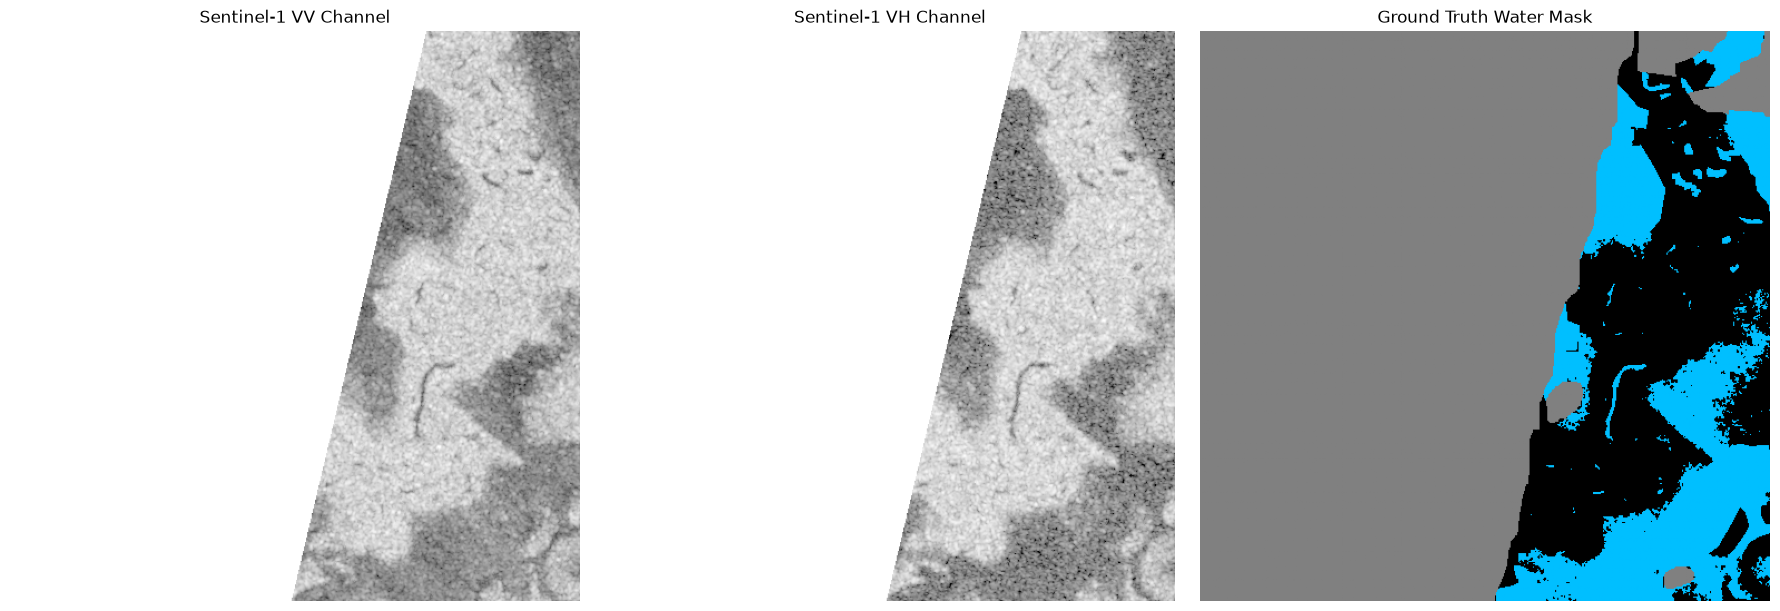

In [8]:
vv = image[0]
vh = image[1]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(vv, cmap="gray")
axes[0].set_title("Sentinel-1 VV Channel")

axes[1].imshow(vh, cmap="gray")
axes[1].set_title("Sentinel-1 VH Channel")

mask_cmap = ListedColormap([
    "gray",
    "black",
    "deepskyblue"
])

norm = BoundaryNorm(
    [-1.5, -0.5, 0.5, 1.5],
    mask_cmap.N
)

axes[2].imshow(mask, cmap=mask_cmap, norm=norm)
axes[2].set_title("Ground Truth Water Mask")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [9]:
labels, counts = np.unique(mask, return_counts=True)

total_pixels = mask.size

for label, count in zip(labels, counts):
    percentage = (count / total_pixels) * 100

    print(
        f"Label {label}: "
        f"{count:,} pixels "
        f"({percentage:.2f}%)"
    )

Label -1: 174,067 pixels (66.40%)
Label 0: 52,715 pixels (20.11%)
Label 1: 35,362 pixels (13.49%)


In [10]:
from tqdm.auto import tqdm

records = []

for sample_id in tqdm(common_ids):

    with rasterio.open(images[sample_id]) as src:
        img = src.read()
        image_crs = src.crs
        image_transform = src.transform

    with rasterio.open(masks[sample_id]) as src:
        target = src.read(1)
        mask_crs = src.crs
        mask_transform = src.transform

    # Validate image and mask
    assert img.shape == (2, 512, 512), sample_id
    assert target.shape == (512, 512), sample_id
    assert image_crs == mask_crs, sample_id
    assert image_transform.almost_equals(mask_transform), sample_id
    assert np.isin(target, [-1, 0, 1]).all(), sample_id

    # Pixel counts
    total = target.size

    invalid = np.sum(target == -1)
    non_water = np.sum(target == 0)
    water = np.sum(target == 1)

    valid = non_water + water

    records.append({
        "sample_id": sample_id,
        "region": sample_id.split("_")[0],
        "total_pixels": total,
        "invalid_pixels": invalid,
        "non_water_pixels": non_water,
        "water_pixels": water,
        "valid_pixels": valid,
        "invalid_ratio": invalid / total,
        "water_ratio": water / valid if valid > 0 else np.nan,
        "non_finite_input_pixels": (
            ~np.isfinite(img).all(axis=0)
        ).sum()
    })

df = pd.DataFrame(records)

df.head()

  0%|          | 0/446 [00:00<?, ?it/s]

,sample_id,region,total_pixels,invalid_pixels,non_water_pixels,water_pixels,valid_pixels,invalid_ratio,water_ratio,non_finite_input_pixels
0,Bolivia_103757,Bolivia,262144,174067,52715,35362,88077,0.664013,0.401490,160521
1,Bolivia_129334,Bolivia,262144,24330,81171,156643,237814,0.092812,0.658679,749
2,Bolivia_195474,Bolivia,262144,809,259784,1551,261335,0.003086,0.005935,0
3,Bolivia_23014,Bolivia,262144,52665,201699,7780,209479,0.200901,0.037140,68586
4,Bolivia_233925,Bolivia,262144,111607,150536,1,150537,0.425747,0.000007,64508


In [11]:
total_pixels = df["total_pixels"].sum()
invalid_pixels = df["invalid_pixels"].sum()
water_pixels = df["water_pixels"].sum()
non_water_pixels = df["non_water_pixels"].sum()

valid_pixels = water_pixels + non_water_pixels

print("Total samples:", len(df))
print(f"Total pixels: {total_pixels:,}")
print(f"Valid pixels: {valid_pixels:,}")
print(f"Invalid pixels: {invalid_pixels:,}")
print(f"Water pixels: {water_pixels:,}")
print(f"Non-water pixels: {non_water_pixels:,}")

print("\nClass Distribution (Valid Pixels Only)")

print(f"Water: {water_pixels / valid_pixels * 100:.2f}%")
print(f"Non-water: {non_water_pixels / valid_pixels * 100:.2f}%")

print(f"\nInvalid pixels: {invalid_pixels / total_pixels * 100:.2f}%")

Total samples: 446
Total pixels: 116,916,224
Valid pixels: 100,983,314
Invalid pixels: 15,932,910
Water pixels: 10,705,605
Non-water pixels: 90,277,709

Class Distribution (Valid Pixels Only)
Water: 10.60%
Non-water: 89.40%

Invalid pixels: 13.63%


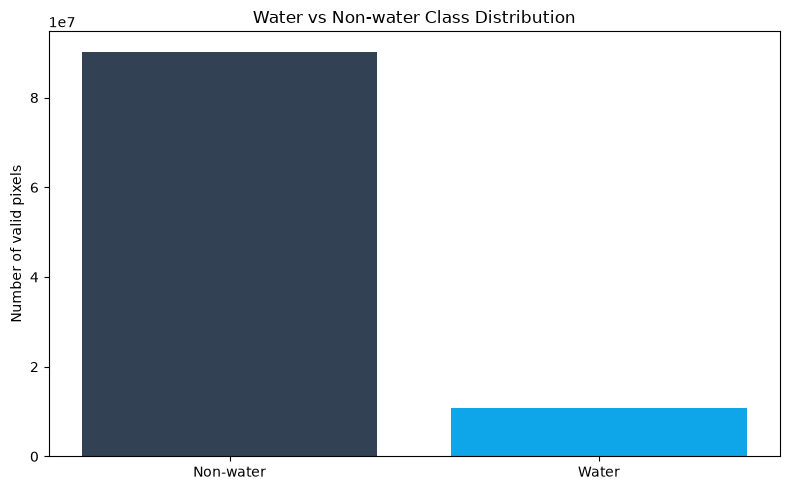

In [12]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    ["Non-water", "Water"],
    [non_water_pixels, water_pixels],
    color=["#334155", "#0ea5e9"]
)

ax.set_title("Water vs Non-water Class Distribution")
ax.set_ylabel("Number of valid pixels")

plt.tight_layout()
plt.show()

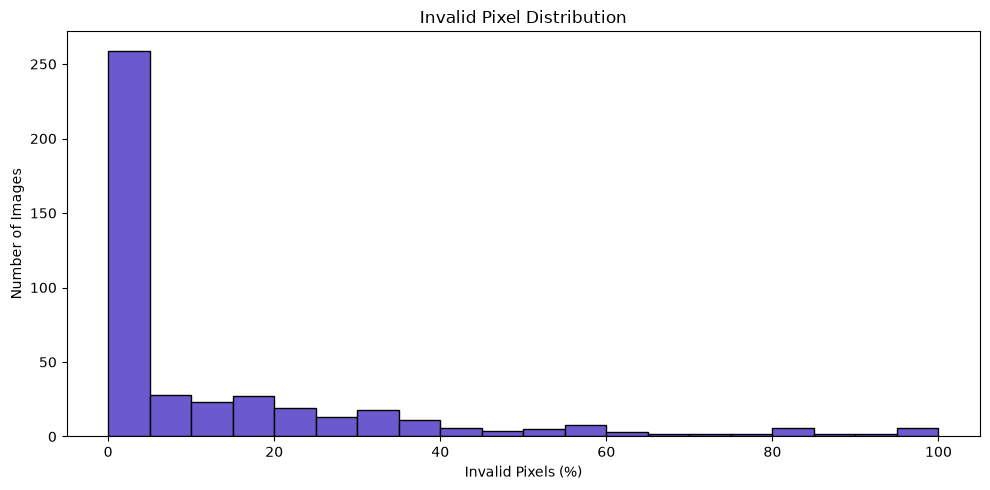

In [13]:
plt.figure(figsize=(10, 5))

plt.hist(
    df["invalid_ratio"] * 100,
    bins=20,
    color="slateblue",
    edgecolor="black"
)

plt.title("Invalid Pixel Distribution")
plt.xlabel("Invalid Pixels (%)")
plt.ylabel("Number of Images")

plt.tight_layout()
plt.show()

region
USA          69
India        68
Paraguay     67
Ghana        53
Sri-Lanka    42
Mekong       30
Spain        30
Pakistan     28
Somalia      26
Nigeria      18
Bolivia      15
Name: count, dtype: int64


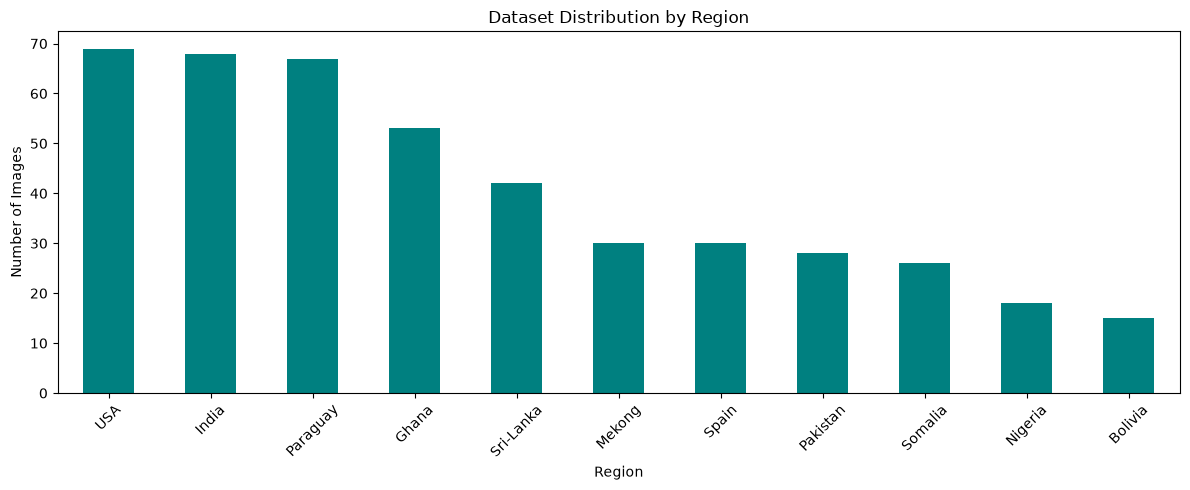

In [14]:
region_counts = df["region"].value_counts()

print(region_counts)

region_counts.plot(
    kind="bar",
    figsize=(12, 5),
    color="teal"
)

plt.title("Dataset Distribution by Region")
plt.xlabel("Region")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [15]:
OUTPUT_DIR = BASE_DIR / "data" / "processed"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

df.to_csv(
    OUTPUT_DIR / "dataset_statistics.csv",
    index=False
)

print("Dataset statistics saved successfully!")

Dataset statistics saved successfully!
